In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
import gseapy as gp

RAW  = Path("../data/raw")
FIG  = Path("../results/figures"); TAB = Path("../results/tables")
CONTRASTS = ["LumB", "Her2", "Basal", "Normal"]
FDR = 0.05
sns.set_theme(style="whitegrid", font_scale=1.0)

# Hallmark gene sets: download once, then reuse the local copy
GMT = RAW / "h.all.gmt"
if not GMT.exists():
    try:                                  # official MSigDB release
        gs = gp.Msigdb().get_gmt(category="h.all", dbver="2024.1.Hs")
        with open(GMT, "w") as f:
            for term, glist in gs.items():
                f.write(term + "\tNA\t" + "\t".join(glist) + "\n")
    except Exception:                     # fallback: MSigDB v7.0 Hallmark file from GSEApy's GitHub
        import urllib.request
        urllib.request.urlretrieve("https://raw.githubusercontent.com/zqfang/GSEApy/master/tests/extdata/h.all.v7.0.symbols.gmt", GMT)
hallmark = gp.read_gmt(str(GMT))
hallmark = {k.replace("HALLMARK_", ""): v for k, v in hallmark.items()}
print(len(hallmark), "Hallmark gene sets")

# DESeq2 results from Step 6
de = {}
for s in CONTRASTS:
    r = pd.read_csv(TAB / f"06_DESeq2_{s}_vs_LumA.csv", index_col=0)
    de[s] = r.dropna(subset=["padj", "stat"])
background = sorted(set(de["Basal"]["gene"].dropna()))      # all tested genes = universe
print("Background:", len(background), "genes")

50 Hallmark gene sets
Background: 15959 genes


Significant Hallmark terms (ORA, BH-FDR < 0.05):
direction  Down  Up
contrast           
Basal         9  14
Her2          5   9
LumB          3   5
Normal        3   9


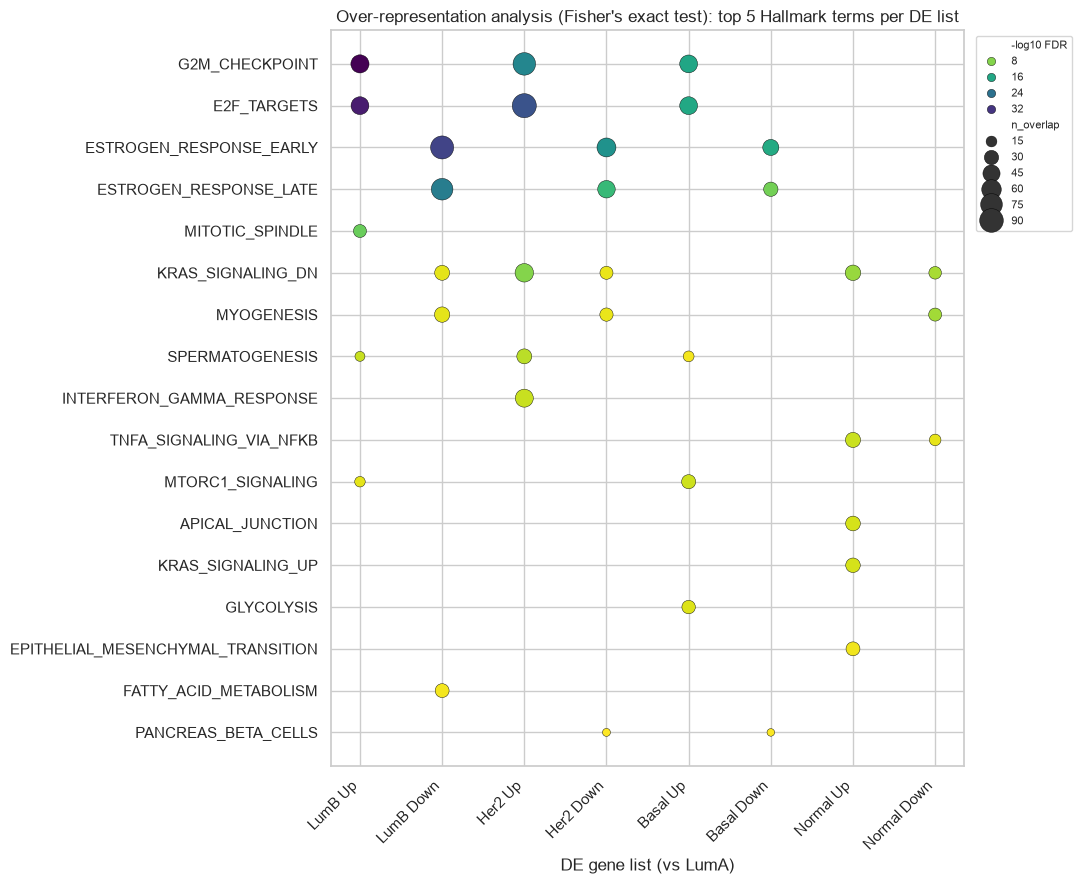

In [2]:
ora_all = []
for s in CONTRASTS:
    for direction in ["Up", "Down"]:
        genes_sig = de[s].loc[de[s]["sig"] == direction, "gene"].dropna().unique().tolist()
        enr = gp.enrich(gene_list=genes_sig, gene_sets=hallmark, background=background, outdir=None, cutoff=1.0)
        res = enr.results.copy()
        res["contrast"], res["direction"], res["n_DE_genes"] = s, direction, len(genes_sig)
        ora_all.append(res)
ora = pd.concat(ora_all, ignore_index=True)
ora["n_overlap"] = ora["Overlap"].str.split("/").str[0].astype(int)
ora = ora[["contrast", "direction", "Term", "Overlap", "n_overlap", "P-value", "Adjusted P-value", "Odds Ratio", "Genes", "n_DE_genes"]]
ora.to_csv(TAB / "07_ORA_hallmark.csv", index=False)
print("Significant Hallmark terms (ORA, BH-FDR < 0.05):")
print(ora[ora["Adjusted P-value"] < FDR].groupby(["contrast", "direction"]).size().unstack(fill_value=0))

top = (ora[ora["Adjusted P-value"] < FDR].sort_values("Adjusted P-value")
          .groupby(["contrast", "direction"]).head(5))
top["group"] = top["contrast"] + " " + top["direction"]
top["-log10 FDR"] = -np.log10(top["Adjusted P-value"].clip(lower=1e-50))
order_x = [f"{c} {d}" for c in CONTRASTS for d in ["Up", "Down"] if f"{c} {d}" in set(top["group"])]
fig, ax = plt.subplots(figsize=(11, 9))
sns.scatterplot(data=top, x="group", y="Term", size="n_overlap", hue="-log10 FDR", palette="viridis_r",
                sizes=(30, 300), ax=ax, edgecolor="black", linewidth=0.3)
ax.set_xticks(range(len(order_x))); ax.set_xticklabels(order_x, rotation=45, ha="right")
ax.set(title="Over-representation analysis (Fisher's exact test): top 5 Hallmark terms per DE list",
       xlabel="DE gene list (vs LumA)", ylabel="")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "07_ORA_dotplot.png", dpi=200); plt.show()

Significant Hallmark sets (GSEA, FDR < 0.05): {'LumB': 34, 'Her2': 29, 'Basal': 20, 'Normal': 27}


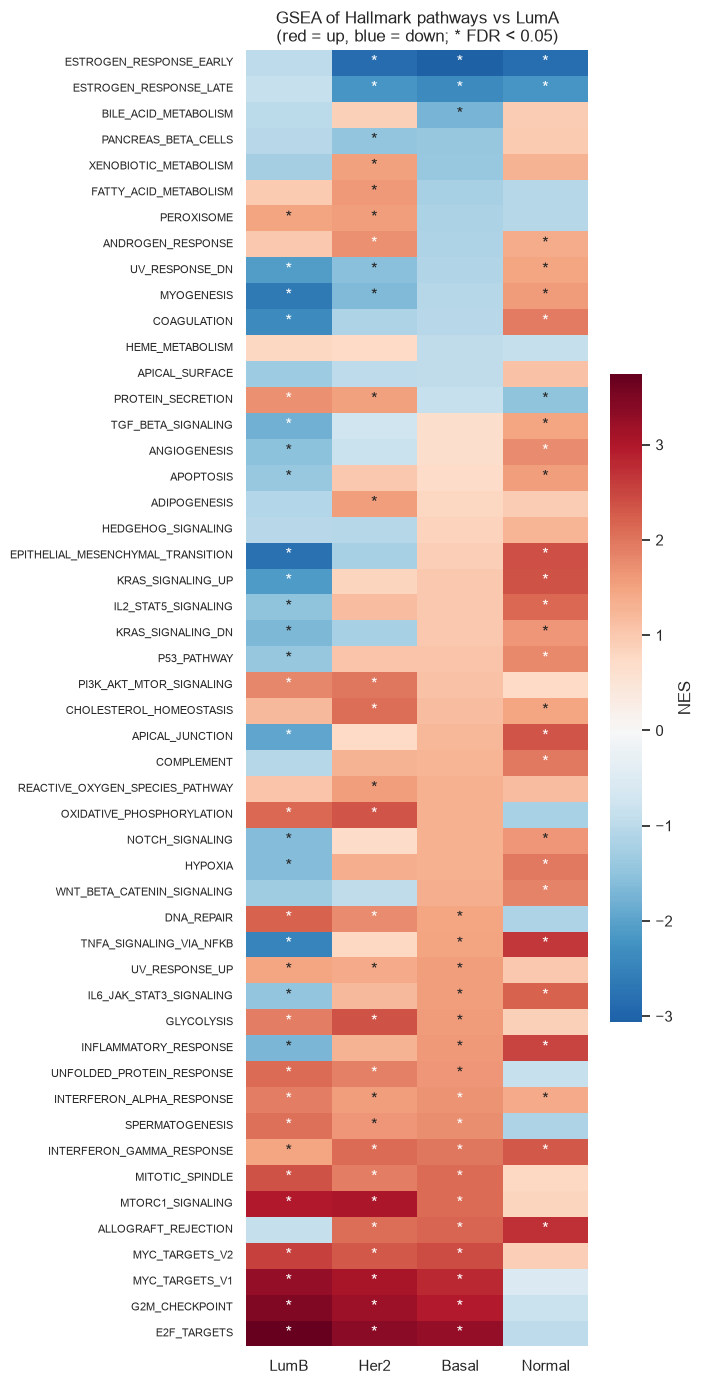


LumB vs LumA  UP:   ['E2F_TARGETS', 'G2M_CHECKPOINT', 'MYC_TARGETS_V1', 'MTORC1_SIGNALING', 'MYC_TARGETS_V2'] 
LumB vs LumA  DOWN: ['EPITHELIAL_MESENCHYMAL_TRANSITION', 'MYOGENESIS', 'TNFA_SIGNALING_VIA_NFKB', 'COAGULATION', 'KRAS_SIGNALING_UP']

Her2 vs LumA  UP:   ['E2F_TARGETS', 'G2M_CHECKPOINT', 'MYC_TARGETS_V1', 'MTORC1_SIGNALING', 'GLYCOLYSIS'] 
Her2 vs LumA  DOWN: ['ESTROGEN_RESPONSE_EARLY', 'ESTROGEN_RESPONSE_LATE', 'MYOGENESIS', 'UV_RESPONSE_DN', 'PANCREAS_BETA_CELLS']

Basal vs LumA  UP:   ['E2F_TARGETS', 'G2M_CHECKPOINT', 'MYC_TARGETS_V1', 'MYC_TARGETS_V2', 'ALLOGRAFT_REJECTION'] 
Basal vs LumA  DOWN: ['ESTROGEN_RESPONSE_EARLY', 'ESTROGEN_RESPONSE_LATE', 'BILE_ACID_METABOLISM']

Normal vs LumA  UP:   ['ALLOGRAFT_REJECTION', 'TNFA_SIGNALING_VIA_NFKB', 'INFLAMMATORY_RESPONSE', 'EPITHELIAL_MESENCHYMAL_TRANSITION', 'KRAS_SIGNALING_UP'] 
Normal vs LumA  DOWN: ['ESTROGEN_RESPONSE_EARLY', 'ESTROGEN_RESPONSE_LATE', 'PROTEIN_SECRETION']


In [3]:
gsea = {}
for s in CONTRASTS:
    rnk = de[s].dropna(subset=["gene"]).groupby("gene")["stat"].mean().sort_values(ascending=False)
    pre = gp.prerank(rnk=rnk, gene_sets=hallmark, permutation_num=1000, min_size=15, max_size=500,
                     seed=42, threads=4, outdir=None, verbose=False)
    r = pre.res2d.copy()
    r[["ES", "NES", "NOM p-val", "FDR q-val"]] = r[["ES", "NES", "NOM p-val", "FDR q-val"]].astype(float)
    r.insert(0, "contrast", s)
    r.to_csv(TAB / f"07_GSEA_{s}_vs_LumA.csv", index=False)
    pre.table = r
    gsea[s] = pre

nes = pd.DataFrame({s: gsea[s].table.set_index("Term")["NES"] for s in CONTRASTS})
fdr = pd.DataFrame({s: gsea[s].table.set_index("Term")["FDR q-val"] for s in CONTRASTS})
nes.to_csv(TAB / "07_GSEA_NES_matrix.csv")
print("Significant Hallmark sets (GSEA, FDR < 0.05):", (fdr < FDR).sum().to_dict())

order = nes.sort_values("Basal").index
stars = fdr.loc[order].map(lambda q: "*" if q < FDR else "")
fig, ax = plt.subplots(figsize=(7, 14))
sns.heatmap(nes.loc[order], cmap="RdBu_r", center=0, annot=stars, fmt="", ax=ax,
            cbar_kws={"label": "NES", "shrink": 0.5})
ax.set(title="GSEA of Hallmark pathways vs LumA\n(red = up, blue = down; * FDR < 0.05)", xlabel="", ylabel="")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.savefig(FIG / "07_GSEA_NES_heatmap.png", dpi=200); plt.show()

for s in CONTRASTS:
    t = gsea[s].table[gsea[s].table["FDR q-val"] < FDR]
    print(f"\n{s} vs LumA  UP:  ", list(t[t["NES"] > 0].nlargest(5, "NES")["Term"]),
          f"\n{s} vs LumA  DOWN:", list(t[t["NES"] < 0].nsmallest(5, "NES")["Term"]))

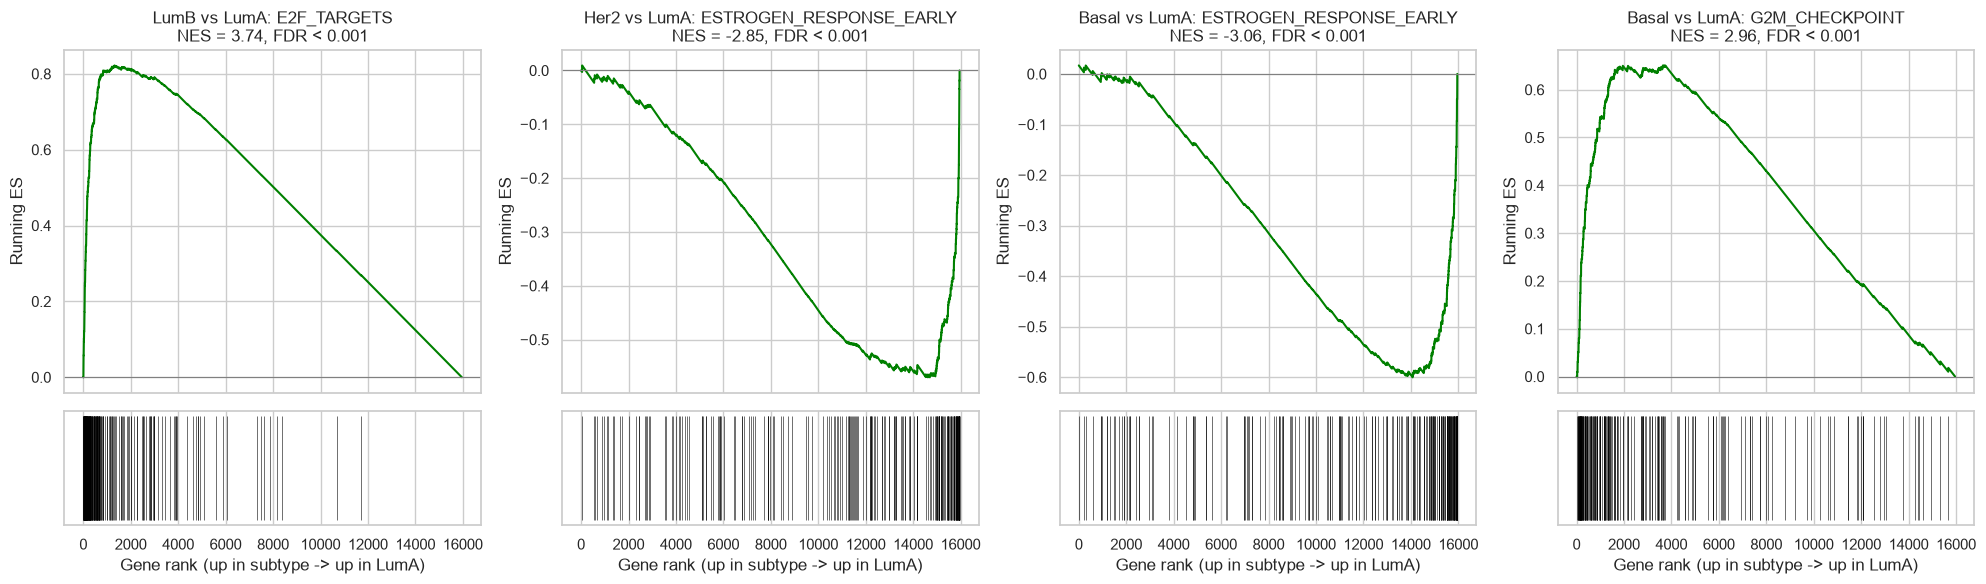

In [4]:
examples = [("LumB", "E2F_TARGETS"), ("Her2", "ESTROGEN_RESPONSE_EARLY"),
            ("Basal", "ESTROGEN_RESPONSE_EARLY"), ("Basal", "G2M_CHECKPOINT")]
fig, axes = plt.subplots(2, 4, figsize=(20, 6), gridspec_kw={"height_ratios": [3, 1]}, sharex="col")
for j, (s, term) in enumerate(examples):
    res = gsea[s].results[term]
    row = gsea[s].table.set_index("Term").loc[term]
    q = row["FDR q-val"]
    q_txt = "FDR < 0.001" if q == 0 else f"FDR = {q:.3f}"     # 1000 permutations -> smallest q = 0.001
    axes[0, j].plot(np.array(res["RES"]), color="green", lw=1.5); axes[0, j].axhline(0, color="grey", lw=0.8)
    axes[0, j].set(title=f"{s} vs LumA: {term}\nNES = {row['NES']:.2f}, {q_txt}", ylabel="Running ES")
    axes[1, j].vlines(res["hits"], 0, 1, color="black", lw=0.4)
    axes[1, j].set(yticks=[], xlabel="Gene rank (up in subtype -> up in LumA)")
plt.tight_layout(); plt.savefig(FIG / "07_GSEA_running_ES.png", dpi=200); plt.show()